# Week 7 timing harness

Times each mystery sorter **one at a time**, as the assignment describes:
start at $n = 16$, add a fixed step, average several fresh random lists per
size, and drop the function when either stopping rule fires. Edit the
settings in the next cell, then run the notebook top to bottom.

In [7]:
%pip install comp271_mystery_sorters

  Using cached comp271_mystery_sorters-0.1.0-py3-none-any.whl.metadata (1.4 kB)
Using cached comp271_mystery_sorters-0.1.0-py3-none-any.whl (3.5 kB)

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [11]:
from __future__ import annotations
import random
import time
from comp271_mystery_sorters import gandalf, saruman, sauron

# ---- Settings: the values you must report in your write-up ----
START_SIZE = 4
STEP = 2                    # 1 or 2; keep it the same for every function
TRIALS = 5                  # fresh random list per trial, then average
MAX_SECONDS_PER_CALL = 5.0  # stop rule 1: a single call is too slow (interrupted)
MAX_SECONDS_TOTAL = 60.0    # stop rule 2: total wall-clock per function
MAX_SIZE = 5000             # hard ceiling, in case a function never slows down
FUNCTIONS = [gandalf, saruman, sauron]

# Per-function overrides. sauron is bogo-style: keep it at n <= 10.
LIMITS = {"sauron": {"start": 4, "max": 10}}

In [12]:
import signal


class CallTooSlow(Exception):
    """Raised when a single call exceeds its time allowance."""


def _on_alarm(signum, frame):
    raise CallTooSlow()


def generate_random_array(size: int, min_value: int = 0, max_value: int = 10_000) -> list[int]:
    """Return a list of `size` random integers in [min_value, max_value]."""
    return [random.randint(min_value, max_value) for _ in range(size)]


def time_once(func, data: list[int], allowance: float) -> float | None:
    """Time one call of func(data), in seconds; None if it exceeds `allowance`.

    The call is interrupted when the allowance runs out, so a function whose
    single call would take minutes (or never finish) cannot hang the notebook.
    Also checks the contract: sorted result, input untouched.
    """
    original = list(data)
    result_time = None
    signal.signal(signal.SIGALRM, _on_alarm)
    signal.setitimer(signal.ITIMER_REAL, max(allowance, 0.001))
    try:
        start = time.perf_counter()
        result = func(data)
        elapsed = time.perf_counter() - start
        signal.setitimer(signal.ITIMER_REAL, 0)
        assert result == sorted(original), f"{func.__name__} did not return the sorted list"
        assert data == original, f"{func.__name__} modified its input"
        result_time = elapsed
    except CallTooSlow:
        result_time = None
    finally:
        signal.setitimer(signal.ITIMER_REAL, 0)
    return result_time


def average_time(func, size: int, trials: int, allowance: float) -> float | None:
    """Average over `trials` calls on new random lists; None if any call times out."""
    total = 0.0
    timed_out = False
    trial = 0
    while trial < trials and not timed_out:
        t = time_once(func, generate_random_array(size), allowance)
        if t is None:
            timed_out = True
        else:
            total += t
        trial += 1
    return None if timed_out else total / trials


def run_experiment(func) -> dict:
    """Step the size up for one function until a stopping rule fires.

    Returns the sizes, the average times, and why it stopped. A step that is
    cut off mid-call is not recorded as a time; the size is in `cut_off_at`.
    """
    sizes, times = [], []
    reason = None
    cut_off_at = None
    start_size = LIMITS.get(func.__name__, {}).get("start", START_SIZE)
    max_size = LIMITS.get(func.__name__, {}).get("max", MAX_SIZE)
    size = start_size
    wall_start = time.perf_counter()
    while reason is None:
        remaining = MAX_SECONDS_TOTAL - (time.perf_counter() - wall_start)
        avg = average_time(func, size, TRIALS, min(MAX_SECONDS_PER_CALL, remaining))
        if avg is None:
            cut_off_at = size
            if remaining < MAX_SECONDS_PER_CALL:
                reason = f"total budget of {MAX_SECONDS_TOTAL}s ran out during n={size}"
            else:
                reason = f"a call at n={size} took longer than {MAX_SECONDS_PER_CALL}s"
        else:
            sizes.append(size)
            times.append(avg)
            if avg > MAX_SECONDS_PER_CALL:
                reason = f"average {avg:.2f}s exceeded {MAX_SECONDS_PER_CALL}s"
            elif time.perf_counter() - wall_start > MAX_SECONDS_TOTAL:
                reason = f"total budget of {MAX_SECONDS_TOTAL}s used up"
            elif size + STEP > max_size:
                reason = f"reached size limit {max_size}"
            size += STEP
    return {"name": func.__name__, "sizes": sizes, "times": times,
            "reason": reason, "cut_off_at": cut_off_at}

## Run (one function at a time)

In [13]:
results = []
for fn in FUNCTIONS:
    r = run_experiment(fn)
    results.append(r)
    if r["sizes"]:
        last = f"last n={r['sizes'][-1]}, avg={r['times'][-1]:.6f}s"
    else:
        last = "no completed sizes"
    print(f"{r['name']:8s} points={len(r['sizes']):5d}  {last}  stopped: {r['reason']}")

gandalf  points= 1959  last n=3920, avg=0.018638s  stopped: total budget of 60.0s used up
saruman  points=  556  last n=1114, avg=0.061977s  stopped: total budget of 60.0s ran out during n=1116
sauron   points=    3  last n=8, avg=0.119231s  stopped: a call at n=10 took longer than 5.0s


## Plot: average time vs. $n$

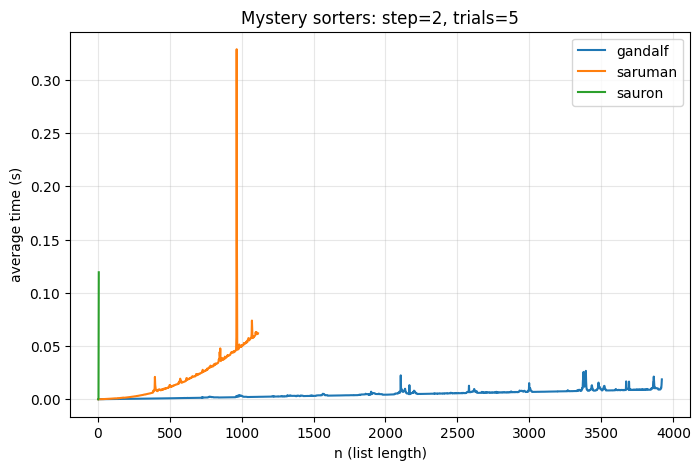

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
for r in results:
    if r["sizes"]:
        ax.plot(r["sizes"], r["times"], label=r["name"])
ax.set_xlabel("n (list length)")
ax.set_ylabel("average time (s)")
ax.set_title(f"Mystery sorters: step={STEP}, trials={TRIALS}")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## Growth exponent

If time scales as $n^k$, then $k \approx \log(t_2/t_1) / \log(n_2/n_1)$.
This uses the mean of the first and last few points, which is less noisy
than a single pair. The very first points are dominated by timer noise, so
treat tiny times with suspicion.

In [15]:
from math import log

def estimate_k(sizes: list[int], times: list[float], window: int = 5) -> float:
    """Estimate k from the means of the first and last `window` points."""
    w = min(window, len(sizes) // 2)
    n1 = sum(sizes[:w]) / w
    t1 = sum(times[:w]) / w
    n2 = sum(sizes[-w:]) / w
    t2 = sum(times[-w:]) / w
    return log(t2 / t1) / log(n2 / n1)

for r in results:
    if len(r["sizes"]) >= 2:
        print(f"{r['name']:8s} k ~ {estimate_k(r['sizes'], r['times']):.2f}")
    else:
        print(f"{r['name']:8s} too few points to estimate k")

gandalf  k ~ 1.19
saruman  k ~ 1.86
sauron   k ~ 11.96


## Sampled table (every 25th point, plus first and last)

In [17]:
for r in results:
    idx = [] if not r["sizes"] else sorted(set(range(0, len(r["sizes"]), 25)) | {len(r["sizes"]) - 1})
    print(r["name"])
    for i in idx:
        print(f"  n={r['sizes'][i]:5d}  avg={r['times'][i]:.6f}s")

gandalf
  n=    4  avg=0.000004s
  n=   54  avg=0.000069s
  n=  104  avg=0.000168s
  n=  154  avg=0.000268s
  n=  204  avg=0.000369s
  n=  254  avg=0.000410s
  n=  304  avg=0.000542s
  n=  354  avg=0.000602s
  n=  404  avg=0.000735s
  n=  454  avg=0.000822s
  n=  504  avg=0.000891s
  n=  554  avg=0.001016s
  n=  604  avg=0.001120s
  n=  654  avg=0.001231s
  n=  704  avg=0.001348s
  n=  754  avg=0.001640s
  n=  804  avg=0.001840s
  n=  854  avg=0.001670s
  n=  904  avg=0.001763s
  n=  954  avg=0.001856s
  n= 1004  avg=0.003006s
  n= 1054  avg=0.002112s
  n= 1104  avg=0.002217s
  n= 1154  avg=0.002367s
  n= 1204  avg=0.002494s
  n= 1254  avg=0.002756s
  n= 1304  avg=0.002692s
  n= 1354  avg=0.003178s
  n= 1404  avg=0.002913s
  n= 1454  avg=0.003015s
  n= 1504  avg=0.003135s
  n= 1554  avg=0.003757s
  n= 1604  avg=0.003371s
  n= 1654  avg=0.003500s
  n= 1704  avg=0.003604s
  n= 1754  avg=0.003714s
  n= 1804  avg=0.003883s
  n= 1854  avg=0.004502s
  n= 1904  avg=0.004813s
  n= 1954  avg=0.